# Part B — Notebook 5: Downstream Tracking

**CSE 445 — Computer Vision | East West University**

Deploys the winning detector from Task 1 (the SSL backbone with the best test mAP50-95 at ρ=0.20 across Notebooks 1b-4b) in a multi-object tracking pipeline (Section 5).

## 0. Setup

In [1]:
!pip install -q ultralytics==8.3.* yt-dlp motmetrics pandas

import os, subprocess, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from ultralytics import YOLO

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.8/183.8 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 89.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.5/161.5 kB 13.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## 1. Config Cell

**Fill in `WINNING_METHOD` and `WINNING_CHECKPOINT_DATASET`** after ranking the four SSL methods by test mAP50-95 in Notebooks 1b-4b's summary tables (Section 4.1's "Selecting the Best SSL Backbone" note).

In [2]:
CONFIG = {
    # ---- Winning detector from Task 1 (fill in after comparing 1b-4b results) ----
    'winning_method': 'dinov3',        # e.g. 'byol', 'dinov3', 'simclr', 'ijepa'
    'checkpoint_dataset': Path('/kaggle/input/notebooks/siyamsalehrahmanrafi/04b-dinov3-backbone-yolov12s-fine-tune/runs/dinov3_ft_rho20/weights'),
    'checkpoint_filename': 'best.pt',   # from the winning *b notebook's Section 13 export

    # ---- Dry run ----
    'dry_run': False,                  # sanity-check the whole pipeline on a short clip first
    'dry_run_clip_duration_sec': 3,   # short clip used only while dry_run=True

    # ---- Video source ----
    # Preference order actually used below: local_video_path -> youtube_url -> synthetic fallback.
    'local_video_path': Path('/kaggle/input/datasets/ayonadhikary777/thermal-video/Produce_a_synthetic_thermal_in.mp4'),
    'youtube_url': '',        # fill in a real YouTube URL containing car/person/dog (or a visually
                               # similar surrogate) — used only if local_video_path is missing
    'clip_start_sec': 0,
    'clip_duration_sec': 20,   # PDF requires a 15-30s trimmed clip (real run only)

    # ---- Tracker ----
    'tracker': 'bytetrack.yaml',   # or 'botsort.yaml'
    'track_conf': 0.25,
    'track_iou': 0.5,

    'imgsz': 640,
    'seed': 42,
    'work_dir': Path('/kaggle/working'),
    'video_dir': Path('/kaggle/working/video'),

    # ---- Ground truth (optional) ----
    # If your group hand-annotated a 10-15s sub-clip (e.g. with CVAT) in MOT-Challenge format,
    # point this at the GT file to run full MOTA/IDF1 evaluation instead of proxy metrics.
    'gt_file': None,   # e.g. Path('/kaggle/input/.../gt.txt')
}
CONFIG['video_dir'].mkdir(parents=True, exist_ok=True)
CONFIG


{'winning_method': 'dinov3',
 'checkpoint_dataset': PosixPath('/kaggle/input/notebooks/siyamsalehrahmanrafi/04b-dinov3-backbone-yolov12s-fine-tune/runs/dinov3_ft_rho20/weights'),
 'checkpoint_filename': 'best.pt',
 'dry_run': False,
 'dry_run_clip_duration_sec': 3,
 'local_video_path': PosixPath('/kaggle/input/datasets/ayonadhikary777/thermal-video/Produce_a_synthetic_thermal_in.mp4'),
 'youtube_url': '',
 'clip_start_sec': 0,
 'clip_duration_sec': 20,
 'tracker': 'bytetrack.yaml',
 'track_conf': 0.25,
 'track_iou': 0.5,
 'imgsz': 640,
 'seed': 42,
 'work_dir': PosixPath('/kaggle/working'),
 'video_dir': PosixPath('/kaggle/working/video'),
 'gt_file': None}

### Dry-Run Toggle

Set `CONFIG['dry_run'] = True` (default) to sanity-check the whole pipeline — video source
resolution, detector loading, tracking inference, and metric extraction — on a very short clip
(`dry_run_clip_duration_sec`) instead of the full 15-30s clip. **This does not produce trustworthy
tracking metrics**; it only proves the notebook runs top-to-bottom without crashing. Set it to
`False` once you're confident the code works, then restart the kernel and re-run from the CONFIG
cell for the real submission run.


In [3]:
if CONFIG['dry_run']:
    CONFIG['clip_duration_sec'] = CONFIG['dry_run_clip_duration_sec']
    print(f"DRY RUN — using a {CONFIG['clip_duration_sec']}s clip only, to confirm the pipeline "
          f"runs end-to-end.")
    print("This run's tracks/metrics are NOT meaningful. Set CONFIG['dry_run'] = False (and "
          "restart the kernel) for the real 15-30s run.")
else:
    print(f"Full run — using a {CONFIG['clip_duration_sec']}s clip.")


Full run — using a 20s clip.


## 2. Load the Winning Detector

Attach the Kaggle dataset published from the winning `*b` notebook's Section 13 export as an input to this notebook, then point `checkpoint_filename` at it.

In [4]:
ckpt_path = CONFIG['checkpoint_dataset'] / CONFIG['checkpoint_filename']
assert ckpt_path.exists(), (
    f'Winning checkpoint not found at {ckpt_path}. Attach the dataset/output published from '
    f'Notebook {CONFIG["winning_method"]}b (Section 13) as an input to this notebook, '
    f'then set CONFIG["checkpoint_dataset"] / CONFIG["checkpoint_filename"] to the exact path.'
)
detector = YOLO(str(ckpt_path))
print('Loaded winning detector:', ckpt_path.name, '| method:', CONFIG['winning_method'])
print('Classes:', detector.names)


Loaded winning detector: best.pt | method: dinov3
Classes: {0: 'car', 1: 'dog', 2: 'person'}


## 3. Video Source

**Preference order per Section 5.1:** (a) a real YouTube video containing the target class or a visually similar surrogate, trimmed to 15-30s; (b) if unavailable, a synthetic clip. This cell tries (a) first via `yt-dlp` and falls back to a simple synthetic OpenCV-rendered clip (moving shapes standing in for car/person/dog) if no URL is given or the download fails — document whichever path actually ran in your report (Section 5.1 requires the source, resolution, and frame rate to be documented either way).

In [5]:
raw_video_path = CONFIG['video_dir'] / 'raw_download.mp4'
trimmed_video_path = CONFIG['video_dir'] / 'clip_trimmed.mp4'
video_source_note = None

def try_download_youtube(url, out_path):
    cmd = ['yt-dlp', '-f', 'mp4[height<=720]/mp4', '-o', str(out_path), url]
    result = subprocess.run(cmd, capture_output=True, text=True, timeout=180)
    return result.returncode == 0 and out_path.exists()

def make_synthetic_clip(out_path, duration_sec=20, fps=24, size=(640, 480)):
    """Fallback: a simple synthetic clip with moving shapes standing in for car/person/dog,
    when no real video is available. Documents its own synthesis parameters for the report."""
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    writer = cv2.VideoWriter(str(out_path), fourcc, fps, size)
    n_frames = duration_sec * fps
    rng = np.random.RandomState(CONFIG['seed'])
    # two moving 'person' blobs and one moving 'car' rectangle, bouncing off the frame edges
    objs = [
        {'pos': np.array([80.0, 200.0]), 'vel': np.array([3.0, 1.5]), 'kind': 'person', 'size': (20, 50)},
        {'pos': np.array([400.0, 100.0]), 'vel': np.array([-2.0, 2.0]), 'kind': 'person', 'size': (18, 45)},
        {'pos': np.array([200.0, 350.0]), 'vel': np.array([2.5, -1.0]), 'kind': 'car', 'size': (70, 35)},
    ]
    for _ in range(n_frames):
        frame = np.full((size[1], size[0], 3), 30, dtype=np.uint8)   # dark background
        cv2.rectangle(frame, (0, size[1]-60), (size[0], size[1]), (50,50,50), -1)  # 'road/ground'
        for obj in objs:
            obj['pos'] += obj['vel']
            w, h = obj['size']
            if obj['pos'][0] < 0 or obj['pos'][0] > size[0]-w: obj['vel'][0] *= -1
            if obj['pos'][1] < 0 or obj['pos'][1] > size[1]-h: obj['vel'][1] *= -1
            x, y = int(obj['pos'][0]), int(obj['pos'][1])
            color = (200,200,50) if obj['kind']=='person' else (50,200,200)
            cv2.rectangle(frame, (x,y), (x+w, y+h), color, -1)
        writer.write(frame)
    writer.release()

# Preference order: (1) local Kaggle-input video, (2) YouTube download, (3) synthetic fallback.
if CONFIG.get('local_video_path') and Path(CONFIG['local_video_path']).exists():
    import shutil
    shutil.copy(CONFIG['local_video_path'], raw_video_path)
    video_source_note = f"Local video (Kaggle input): {CONFIG['local_video_path']}"

if video_source_note is None and CONFIG['youtube_url']:
    ok = try_download_youtube(CONFIG['youtube_url'], raw_video_path)
    if ok:
        video_source_note = f"Real YouTube video: {CONFIG['youtube_url']}"
    else:
        print('yt-dlp download failed — falling back to synthetic clip.')

if video_source_note is None:
    make_synthetic_clip(raw_video_path, duration_sec=CONFIG['clip_duration_sec'])
    video_source_note = (
        'Synthetic OpenCV-rendered clip (no local/YouTube source configured or download failed): '
        'moving rectangles standing in for person/car targets, documented per Section 5.1(b). '
        'NOTE FOR YOUR REPORT: replace CONFIG["local_video_path"]/["youtube_url"] with a real clip '
        'if at all possible — a synthetic clip this simple will not exercise real detector/tracker '
        'failure modes (occlusion, motion blur, lighting) that Section 5.2 asks you to analyse.'
    )

print(video_source_note)


Local video (Kaggle input): /kaggle/input/datasets/ayonadhikary777/thermal-video/Produce_a_synthetic_thermal_in.mp4


In [6]:
# Trim to the configured window and report actual resolution/fps (required documentation)
cap = cv2.VideoCapture(str(raw_video_path))
src_fps = cap.get(cv2.CAP_PROP_FPS) or 24
src_w, src_h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()

start_f = int(CONFIG['clip_start_sec'] * src_fps)
end_f = min(total_frames, start_f + int(CONFIG['clip_duration_sec'] * src_fps))

cap = cv2.VideoCapture(str(raw_video_path))
cap.set(cv2.CAP_PROP_POS_FRAMES, start_f)
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
writer = cv2.VideoWriter(str(trimmed_video_path), fourcc, src_fps, (src_w, src_h))
f = start_f
while f < end_f:
    ret, frame = cap.read()
    if not ret: break
    writer.write(frame)
    f += 1
cap.release(); writer.release()

clip_duration_actual = (end_f - start_f) / src_fps
print(f'Trimmed clip: {trimmed_video_path.name} | {src_w}x{src_h} @ {src_fps:.1f} fps | '
      f'{clip_duration_actual:.1f}s ({end_f-start_f} frames)')

if CONFIG['dry_run']:
    print(f'DRY RUN clip duration: {clip_duration_actual:.1f}s (15-30s bounds check skipped)')
else:
    assert 10 <= clip_duration_actual <= 35, 'Aim for a 15-30s clip per Section 5.1 (a little slack either side is fine).'


Trimmed clip: clip_trimmed.mp4 | 1280x720 @ 24.0 fps | 10.0s (240 frames)


## 4. Tracking Inference

Uses Ultralytics' built-in `track()` interface with ByteTrack (default) or BoT-SORT. Association parameters (track buffer, match thresholds) are the tracker YAML's defaults — documented explicitly below per Section 5.1 point 2.

In [7]:
# Document association parameters (Section 5.1 point 2 requirement)
import yaml as _yaml, ultralytics, os as _os
tracker_yaml_path = _os.path.join(_os.path.dirname(ultralytics.__file__), 'cfg', 'trackers', CONFIG['tracker'])
if _os.path.exists(tracker_yaml_path):
    with open(tracker_yaml_path) as f:
        tracker_params = _yaml.safe_load(f)
    print(f"Association parameters for {CONFIG['tracker']}:")
    for k, v in tracker_params.items():
        print(f'  {k}: {v}')
else:
    print('Could not locate tracker YAML on disk — parameters are the ultralytics package defaults for', CONFIG['tracker'])

Association parameters for bytetrack.yaml:
  tracker_type: bytetrack
  track_high_thresh: 0.25
  track_low_thresh: 0.1
  new_track_thresh: 0.25
  track_buffer: 30
  match_thresh: 0.8
  fuse_score: True


In [8]:
track_results_dir = CONFIG['work_dir'] / 'tracking_run'
track_results = detector.track(
    source=str(trimmed_video_path),
    tracker=CONFIG['tracker'],
    conf=CONFIG['track_conf'],
    iou=CONFIG['track_iou'],
    imgsz=CONFIG['imgsz'],
    save=True,
    project=str(CONFIG['work_dir']),
    name='tracking_run',
    exist_ok=True,
    persist=True,
    verbose=False,
)
print(f'Processed {len(track_results)} frames. Annotated video saved under {CONFIG["work_dir"] / "tracking_run"}')

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.12.13 environment at: /usr
Resolved 2 packages in 210ms
 Downloaded lap
Prepared 1 package in 32ms
Installed 1 package in 5ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.7s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

Results saved to /kaggle/working/tracking_run
Processed 240 frames. Annotated video sa

### Save Representative Frames

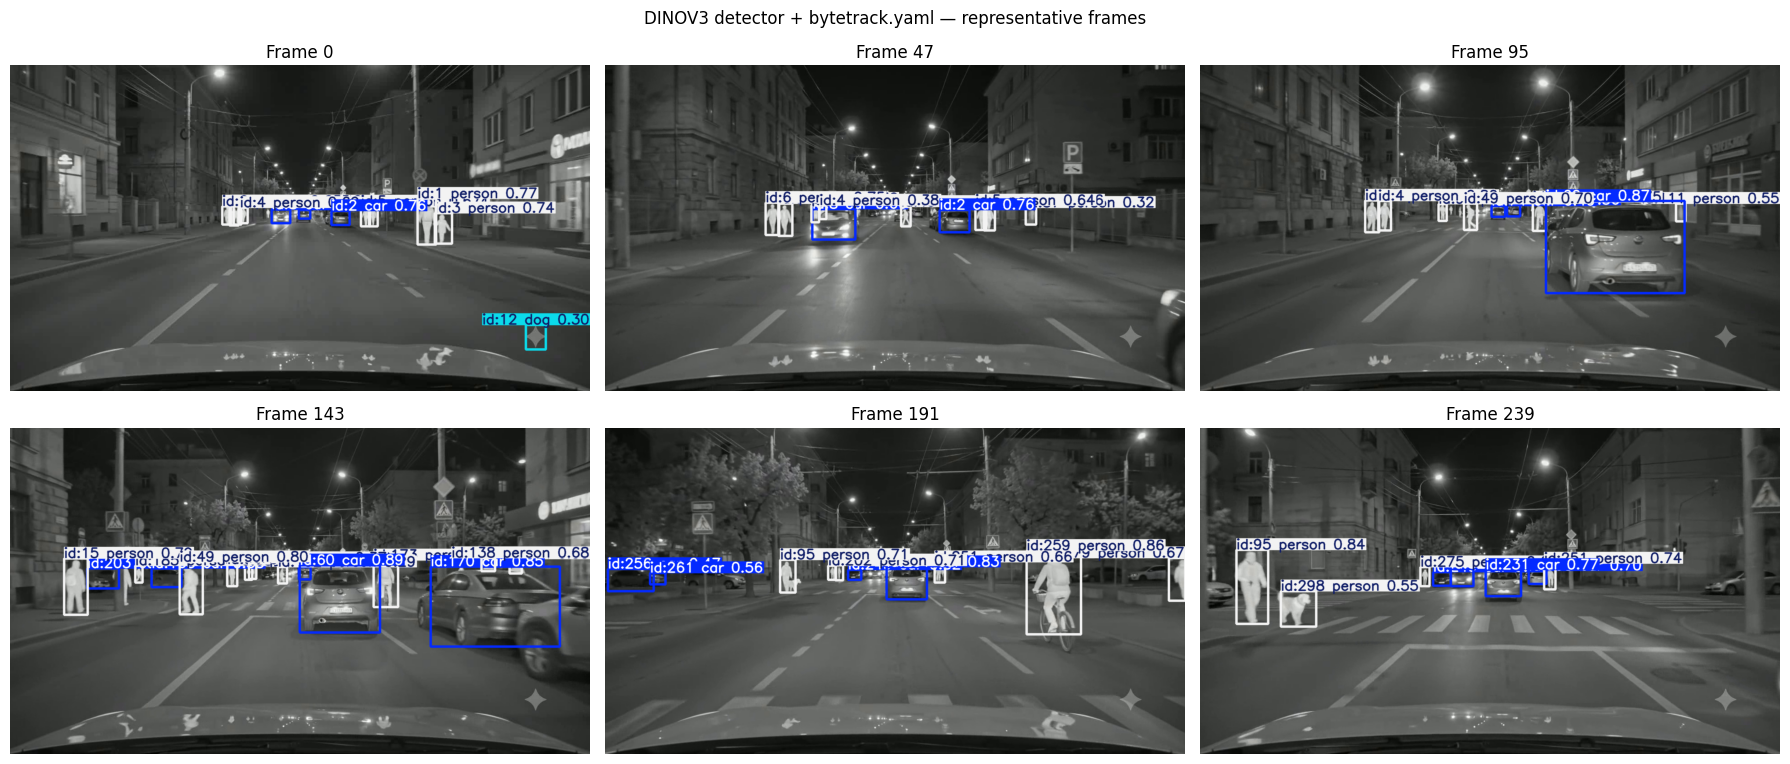

In [9]:
sample_frame_idxs = np.linspace(0, len(track_results)-1, 6).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, idx in zip(axes.flatten(), sample_frame_idxs):
    frame_bgr = track_results[idx].plot()
    ax.imshow(frame_bgr[..., ::-1]); ax.axis('off'); ax.set_title(f'Frame {idx}')
plt.suptitle(f'{CONFIG["winning_method"].upper()} detector + {CONFIG["tracker"]} — representative frames')
plt.tight_layout()
plt.savefig(CONFIG['work_dir'] / 'tracking_representative_frames.jpg', dpi=150)
plt.show()

## 5. Extract Per-Frame Track Records

Builds a flat table of `(frame, track_id, class, x, y, w, h, conf)` — the basis for both the proxy metrics and (if you have GT) the motmetrics evaluation below.

In [10]:
records = []
for frame_idx, res in enumerate(track_results):
    if res.boxes is None or res.boxes.id is None:
        continue
    boxes = res.boxes.xywh.cpu().numpy()
    ids = res.boxes.id.cpu().numpy().astype(int)
    clss = res.boxes.cls.cpu().numpy().astype(int)
    confs = res.boxes.conf.cpu().numpy()
    for (x, y, w, h), tid, cls, conf in zip(boxes, ids, clss, confs):
        records.append({'frame': frame_idx, 'track_id': int(tid), 'class': detector.names[int(cls)],
                         'x': x, 'y': y, 'w': w, 'h': h, 'conf': float(conf)})

track_df = pd.DataFrame(records)
track_df.to_csv(CONFIG['work_dir'] / 'track_records.csv', index=False)
print(f'{len(track_df)} detections across {track_df["frame"].nunique() if len(track_df) else 0} frames, '
      f'{track_df["track_id"].nunique() if len(track_df) else 0} unique track IDs')
track_df.head()

2631 detections across 240 frames, 84 unique track IDs


,frame,track_id,class,x,y,w,h,conf
0,0,1,person,919.817993,346.791382,41.208496,101.046509,0.773578
1,0,2,car,729.624268,339.018280,40.716064,31.157288,0.757181
2,0,3,person,956.907288,362.036926,37.880859,66.692810,0.740392
3,0,4,person,515.601135,333.168213,16.824219,33.887939,0.687771
4,0,5,person,784.943848,335.544708,20.050537,43.172424,0.665997


## 6. Tracker Evaluation

**If `CONFIG['gt_file']` is set** (your group hand-annotated a sub-clip, e.g. with CVAT, in MOT-Challenge format): runs full MOTA/MOTP/IDF1/ID-switches/MT-ML via `motmetrics`. **Otherwise** (the common case without ground truth): reports the proxy metrics required by Section 5.2's "No ground truth" row.

No GT file configured — reporting proxy metrics (Section 5.2 "No ground truth" row).



,unique_track_ids,mean_track_length_frames,fragmentation_events,mean_detection_confidence,inference_fps
0,84,31.32,62,0.6617,24.0


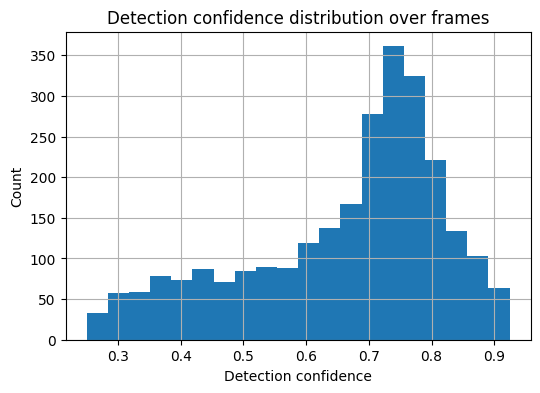

NOTE: "ID-switch events counted by manual inspection of the rendered video" (Section 5.2) cannot be automated — watch the saved annotated video under /kaggle/working/tracking_run and record switches you observe by eye for the report.


In [11]:
if CONFIG['gt_file'] is not None and Path(CONFIG['gt_file']).exists():
    import motmetrics as mm
    gt = mm.io.loadtxt(str(CONFIG['gt_file']), fmt='mot15-2D')
    pred_mot_path = CONFIG['work_dir'] / 'pred_mot.txt'
    with open(pred_mot_path, 'w') as f:
        for _, r in track_df.iterrows():
            f.write(f"{r['frame']+1},{r['track_id']},{r['x']-r['w']/2:.2f},{r['y']-r['h']/2:.2f},"
                    f"{r['w']:.2f},{r['h']:.2f},{r['conf']:.4f},-1,-1,-1\n")
    pred = mm.io.loadtxt(str(pred_mot_path), fmt='mot15-2D')
    acc = mm.utils.compare_to_groundtruth(gt, pred, 'iou', distth=0.5)
    mh = mm.metrics.create()
    summary = mh.compute(acc, metrics=['mota', 'motp', 'idf1', 'num_switches',
                                        'mostly_tracked', 'mostly_lost'], name='tracker')
    print(mm.io.render_summary(summary, formatters=mh.formatters, namemap=mm.io.motchallenge_metric_names))
    summary.to_csv(CONFIG['work_dir'] / 'mot_metrics.csv')
else:
    print('No GT file configured — reporting proxy metrics (Section 5.2 "No ground truth" row).\n')

    n_unique_ids = track_df['track_id'].nunique() if len(track_df) else 0
    track_lengths = track_df.groupby('track_id').size() if len(track_df) else pd.Series(dtype=int)
    mean_track_length = track_lengths.mean() if len(track_lengths) else 0
    # fragmentation proxy: tracks whose frame indices have gaps (track lost then re-acquired under a new/old ID)
    def count_gaps(frames):
        frames = sorted(frames)
        return sum(1 for a, b in zip(frames, frames[1:]) if b - a > 1)
    frag_count = track_df.groupby('track_id')['frame'].apply(lambda s: count_gaps(list(s))).sum() if len(track_df) else 0
    fps_estimate = len(track_results) / max(1e-6, clip_duration_actual)

    proxy_metrics = pd.DataFrame([{
        'unique_track_ids': n_unique_ids,
        'mean_track_length_frames': round(float(mean_track_length), 2),
        'fragmentation_events': int(frag_count),
        'mean_detection_confidence': round(float(track_df['conf'].mean()) if len(track_df) else 0.0, 4),
        'inference_fps': round(float(fps_estimate), 2),
    }])
    proxy_metrics.to_csv(CONFIG['work_dir'] / 'proxy_tracking_metrics.csv', index=False)
    display(proxy_metrics)

    plt.figure(figsize=(6,4))
    track_df['conf'].hist(bins=20)
    plt.xlabel('Detection confidence'); plt.ylabel('Count'); plt.title('Detection confidence distribution over frames')
    plt.savefig(CONFIG['work_dir'] / 'confidence_distribution.png', dpi=150)
    plt.show()

    print('NOTE: "ID-switch events counted by manual inspection of the rendered video" (Section 5.2) '
          'cannot be automated — watch the saved annotated video under',
          CONFIG['work_dir'] / 'tracking_run', 'and record switches you observe by eye for the report.')

## 7. Closing Analysis (fill in after watching the annotated video)

*(Required by Section 5.2 — write this after reviewing the rendered video and the metrics above.)*

- **Where the tracker succeeds:**
- **Where identities are lost, and why** (occlusion / motion blur / camera shake / appearance change):
- **How detector quality (from the Task 1 comparison in 1b-4b) propagated into tracking quality:**
- **Video source used:** *(filled by Section 3 above — record `video_source_note` here)*

## 8. Viva Prep — Notes to Fill In (Notebook 5)

- Tracking-by-detection paradigm, and why tracker quality depends on detector mAP:
- How ByteTrack uses low-confidence detections to reduce ID switches:
- MOTA vs. IDF1 — which failure types each punishes, and how a tracker can have high MOTA but low IDF1:
- What BoT-SORT adds over ByteTrack, and when it matters:
- Domain gap observed between training images and the video, and how it showed up in the tracks:
- If synthetic/AI-generated video was used: risks of evaluating on it, and how you mitigated them: